# Cellwise robust regression with cellLTS

Classical robust regression estimators such as LTS or MM protect against outlying *cases*:
they downweight whole rows. In many data sets the predictors instead contain outlying *cells*:
a single wrongly recorded value in an otherwise ordinary row. When the predictors are many,
most rows contain at least one such cell, so casewise methods lose most of the data, and they
cannot handle missing values at all.

`CellLTSRegression` implements cellLTS of

> Raymaekers, J., & Rousseeuw, P. J. (2026). *Least trimmed squares regression with missing
> values and cellwise outliers.* arXiv:2603.04632.

It fits a linear regression when the predictors contain cellwise outliers and missing values
and the response contains outliers. In short:

1. The location and covariance matrix of the predictors are estimated with cellMCD
   (`robpy.covariance.CellMCD`), on differences of pairs of observations so that the fit is
   free of the intercept.
2. Outlying cells of the predictors are flagged and, like missing cells, imputed by their
   conditional expectation given the other cells of the same row.
3. Reweighted LTS on (differences of) the imputed predictors gives the slopes; cases with
   a large standardized residual are flagged.

The implementation follows the authors' R code; with the same random choices it reproduces
its results.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from robpy.datasets import load_topgear
from robpy.regression import CellLTSRegression

## Simulated data

We generate data from a linear model with three correlated predictors and replace 5% of the
predictor cells by the value 10, so that about 14% of the rows contain an outlying cell.

In [2]:
rng = np.random.default_rng(0)
n, beta = 500, np.array([1.0, -2.0, 0.5])
X = np.sqrt(0.5) * rng.normal(size=(n, 1)) + np.sqrt(0.5) * rng.normal(size=(n, 3))
y = 2.0 + X @ beta + 0.5 * rng.normal(size=n)

cells = rng.random(X.shape) < 0.05
X_contaminated = X.copy()
X_contaminated[cells] = 10.0
print(f"rows with an outlying cell: {cells.any(axis=1).mean():.0%}")

rows with an outlying cell: 14%


In [3]:
model = CellLTSRegression().fit(X_contaminated, y)
ols = np.linalg.lstsq(np.column_stack([np.ones(n), X_contaminated]), y, rcond=None)[0]

pd.DataFrame(
    {"true": np.r_[2.0, beta], "cellLTS": np.r_[model.intercept_, model.coef_], "OLS": ols},
    index=["intercept", "x1", "x2", "x3"],
).round(3)

,true,cellLTS,OLS
intercept,2.0,1.967,2.243
x1,1.0,1.038,0.029
x2,-2.0,-1.960,-0.186
x3,0.5,0.475,-0.006


cellLTS recovers the coefficients, while least squares is strongly biased. The outlying cells
are flagged in `cellwise_outliers_`:

In [4]:
print(f"outlying cells flagged: {model.cellwise_outliers_[cells].mean():.1%}")
print(f"clean cells flagged:    {model.cellwise_outliers_[~cells].mean():.1%}")

outlying cells flagged: 100.0%
clean cells flagged:    1.2%


## Car prices

The TopGear data contain 297 cars with their price and technical characteristics, with
missing values and some erroneous cells. We model the log of the price. The skewed
predictors are log-transformed, and we keep the cars with at least 6 of the 10 predictors.

In [5]:
data = load_topgear(as_frame=True).data
data.index = data["Make"] + " " + data["Model"]
columns = ["Displacement", "BHP", "Torque", "Acceleration", "TopSpeed", "MPG",
           "Weight", "Length", "Width", "Height"]
X = data[columns].copy()
for column in ["Displacement", "BHP", "Torque", "Weight", "MPG"]:
    X[column] = np.log(X[column])
y = np.log(data["Price"]).rename("log(Price)")

keep = X.notna().sum(axis=1) >= 6
X, y = X[keep], y[keep]
print(f"{X.shape[0]} cars, {int(X.isna().sum().sum())} missing cells")

293 cars, 79 missing cells


In [6]:
model = CellLTSRegression().fit(X, y)

complete = X.notna().all(axis=1)
ols = np.linalg.lstsq(
    np.column_stack([np.ones(complete.sum()), X[complete]]), y[complete], rcond=None
)[0]
pd.DataFrame(
    {"cellLTS": np.r_[model.intercept_, model.coef_], "OLS (complete cases)": ols},
    index=["intercept"] + columns,
).round(4)

,cellLTS,OLS (complete cases)
intercept,-0.7403,-2.5270
Displacement,0.1535,0.4106
BHP,0.8889,0.7046
Torque,0.1750,0.1528
Acceleration,0.0738,0.0665
TopSpeed,0.0022,0.0103
MPG,0.0168,0.2386
Weight,0.4072,0.1536
Length,-0.0002,-0.0001
Width,0.0013,0.0012


cellLTS uses all cars, including the incomplete ones, and is not affected by the outlying
cells. For example, it flags the fuel consumption (MPG) of electric and hybrid cars and of some
very economical diesels, whose official values do not follow the relation with the other
characteristics (the imputed values are what the other characteristics predict):

In [7]:
mpg = columns.index("MPG")
flagged = model.cellwise_outliers_[:, mpg]
pd.DataFrame(
    {"MPG": np.exp(X["MPG"][flagged]), "imputed": np.exp(model.X_imputed_[flagged, mpg])}
).round(0).sort_values("MPG", ascending=False).head(8)

,MPG,imputed
BMW i3,470.0,42.0
Chevrolet Volt,235.0,46.0
Vauxhall Ampera,235.0,62.0
Citroen DS5,80.0,36.0
Peugeot 3008,80.0,36.0
Mini Convertible,70.0,46.0
Volvo S80,61.0,44.0
Volvo V60,61.0,43.0


The cell map shows the standardized residual of the response and the standardized deviation
of each predictor cell from its imputed value, here for the 12 cars with the largest absolute
standardized residuals. Red cells are higher and blue cells lower than predicted, blank cells
are missing. The numbers are the observed values (on the log scale for the transformed
predictors and the price).

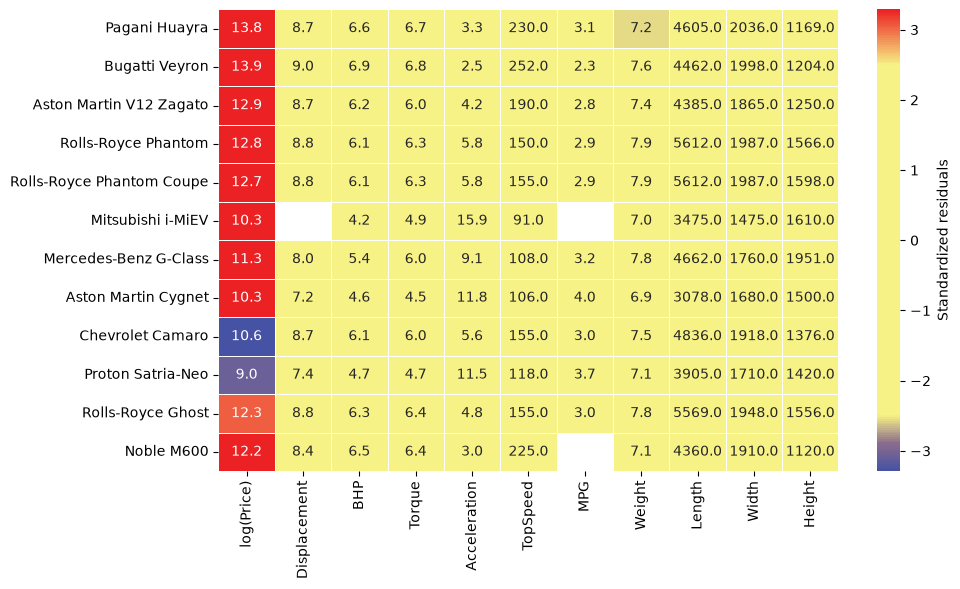

In [8]:
rows = np.argsort(-np.abs(model.standardized_residuals_))[:12]
ax = model.cellmap(X, y, rows=rows, annotate=True, fmt=".1f", figsize=(10, 6))
plt.show()

The most outlying cases are cars that are much more expensive than their characteristics
predict, such as the Pagani Huayra and the Bugatti Veyron. These cases are flagged in
`case_weights_` (weight 0) and do not influence the fit.

New cars, possibly with missing values or outlying cells, are predicted with `predict`, which
first imputes their missing and flagged cells:

In [9]:
new_car = X.iloc[[0]].copy()
new_car["Weight"] = np.nan
print(f"observed price {np.exp(y.iloc[0]):.0f}, predicted {np.exp(model.predict(new_car)[0]):.0f}")

observed price 21250, predicted 20947
